<a href="https://colab.research.google.com/github/Lerreto/Inpainting-Numerical-Project-2026/blob/juan/image_inpainting_organized.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Inpainting Restoration Problem

## Authors

| Name | Student ID | Program |
|---|---|---|
| Pedro Moises Marin Angarita | 2242059 | Systems Engineering |
| Juan Pablo Rueda Angarita | 2250160 | Systems Engineering |

## Table of Contents

- [Authors](#scrollTo=authors)
- [Pipeline Overview](#scrollTo=pipeline)
- [1. Problem Statement](#scrollTo=sec_1)
  - [1.1 Objective](#scrollTo=sec_1_1)
  - [1.2 Experimental Protocol](#scrollTo=sec_1_2)
  - [1.3 Activities](#scrollTo=sec_1_3)
- [2. Improvement Difficulty Levels](#scrollTo=sec_2)
  - [2.1 Fixed Components (Cannot Be Changed)](#scrollTo=sec_2_1)
  - [2.2 Allowed Modifications](#scrollTo=sec_2_2)
  - [2.3 Level 1 — Easy](#scrollTo=sec_2_3)
  - [2.4 Level 2 — Medium](#scrollTo=sec_2_4)
  - [2.5 Level 3 — Hard](#scrollTo=sec_2_5)
  - [2.6 Recommendation](#scrollTo=sec_2_6)
- [3. Setup and Data](#scrollTo=sec_3)
  - [3.1 Import Libraries and Set Reproducibility](#scrollTo=sec_3_1)
  - [3.2 Download the BSDS500 Dataset](#scrollTo=sec_3_2)
  - [3.3 Utility Functions](#scrollTo=sec_3_3)
  - [3.4 Random-Mask Corruption](#scrollTo=sec_3_4)
  - [3.5 Dataset Loader](#scrollTo=sec_3_5)
- [4. Model Architectures](#scrollTo=sec_4)
  - [4.1 Architecture Overview](#scrollTo=sec_4_1)
  - [4.2 Deep Neural Network](#scrollTo=sec_4_2)
  - [4.3 FRRN With and Without Skip Connections](#scrollTo=sec_4_3)
- [5. Training Configuration](#scrollTo=sec_5)
  - [5.1 What Did We Add?](#scrollTo=sec_5_1)
  - [5.2 Why Didn't We Stick With Only Modifying the Hyperparameters?](#scrollTo=sec_5_2)
  - [5.3 Model Hyperparameters, Optimizer, and Loss](#scrollTo=sec_5_3)
- [6. Data Inspection and Baseline](#scrollTo=sec_6)
  - [6.1 Load Dataset and Visualize Samples](#scrollTo=sec_6_1)
  - [6.2 Corrupted-Input Baseline Evaluation](#scrollTo=sec_6_2)
- [7. Training](#scrollTo=sec_7)
  - [7.1 Training Loop](#scrollTo=sec_7_1)
  - [7.2 Training Curves](#scrollTo=sec_7_2)
  - [7.3 Learning Rate Schedule](#scrollTo=sec_7_3)
- [8. Evaluation](#scrollTo=sec_8)
  - [8.1 Baseline vs Restored Image](#scrollTo=sec_8_1)
  - [8.2 Visual Inference](#scrollTo=sec_8_2)
  - [8.3 Image Visualization With Absolute Errors](#scrollTo=sec_8_3)
  - [8.4 Clean Target Histograms](#scrollTo=sec_8_4)
  - [8.5 Prediction Histograms](#scrollTo=sec_8_5)
- [9. Run Tracking](#scrollTo=sec_9)
  - [9.1 Save Results](#scrollTo=sec_9_1)
  - [9.2 View Saved Runs](#scrollTo=sec_9_2)

## Pipeline Overview

The notebook restores images with missing pixels. Run the cells from top to bottom, and choose the model and training options in Section 5.3.

```text
+------------------------------------------------------------------+
| 1. DATA AND PREPROCESSING                    (Sections 3.2, 3.5) |
| BSDS500 images are the clean targets x                           |
| Train: random 96x96 crop + horizontal flip                       |
| Validation: centered 288x288 crop                                |
+------------------------------------------------------------------+
                                 |
                                 v
+------------------------------------------------------------------+
| 2. CORRUPTION: y = m * x                           (Section 3.4) |
| Each pixel is kept with probability 0.80 (about 20% missing)     |
| Train: new random mask per sample                                |
| Validation: fixed mask per image                                 |
+------------------------------------------------------------------+
                                 |
                                 v
+------------------------------------------------------------------+
| 3. MODEL: x_hat = f(y)                               (Section 4) |
| DeepNeuralNetwork | FRRNLite | FRRNLiteNoSkip                    |
| FRRN option: data consistency copies the known pixels from y     |
+------------------------------------------------------------------+
                                 |
                                 v
+------------------------------------------------------------------+
| 4. TRAINING                                      (Sections 5, 7) |
| Loss(x_hat, x) -> backpropagation -> optimizer step              |
| Optional cosine learning-rate schedule                           |
| After each epoch: validate with PSNR and SSIM                    |
| Keep the best checkpoint; stop early after `patience` epochs     |
+------------------------------------------------------------------+
                                 |
                                 v
+------------------------------------------------------------------+
| 5. EVALUATION                                        (Section 8) |
| Reload the best checkpoint                                       |
| Corrupted-input baseline vs restored image (PSNR, SSIM)          |
| Visual inference, absolute errors, and histograms                |
+------------------------------------------------------------------+
                                 |
                                 v
+------------------------------------------------------------------+
| 6. RUN TRACKING                                      (Section 9) |
| Save hyperparameters, metrics, plots, and best model to Drive    |
| Compare the saved runs in the viewer                             |
+------------------------------------------------------------------+
```

# 1. Problem Statement

Image inpainting is an inverse problem in which an observed image $\mathbf{y}$ contains missing pixels from a clean image $\mathbf{x}$:

$$
\mathbf{y}=\mathbf{m}\odot\mathbf{x},
$$

where $\mathbf{m}\in\{0,1\}^{H\times W}$ is a binary mask and $\odot$ denotes element-wise multiplication. In this baseline, each pixel is retained with probability $0.8$; therefore approximately $20\%$ of the spatial samples are removed. Training masks are resampled online, while validation/test masks are deterministic per image.

## 1.1 Objective

Develop a deep-learning model that estimates $\hat{\mathbf{x}}=f_\theta(\mathbf{y})$ from corrupted observations with missing pixels.

## 1.2 Experimental Protocol

- Dataset: BSDS500, matching the other image-restoration projects.
- Training crops: $96\times96$ with random crop and horizontal flip.
- Validation crop: centered $288\times288$.
- Fixed corruption level: pixel retention probability $p=0.8$ (approximately $20\%$ missing samples).
- Training masks are resampled online; validation/test masks are deterministic per image.
- Backbone: same compact residual CNN family used in the other projects.
- Loss: MSE by default.
- Metrics: PSNR and SSIM.
- Validation uses inference mode and the best validation checkpoint is restored.
- The corrupted input itself is reported as a baseline.

## 1.3 Activities

1. Improve the baseline performance by changing optimization, loss, capacity, augmentation, or architecture.
2. Compare the restored result against the corrupted-input baseline.
3. Document quantitative and visual results in an academic report.

# 2. Improvement Difficulty Levels

To improve the baseline model, use the following difficulty guide.

## 2.1 Fixed Components (Cannot Be Changed)

- **Dataset:** keep the BSDS500 dataset exactly as provided.
- **Corruption process:** keep the provided inpainting corruption process fixed. Do not remove it, replace it, or redesign it.

## 2.2 Allowed Modifications

You may improve the model by modifying the training pipeline and/or the neural network, for example:
- hyperparameter tuning
- preprocessing choices
- optimizer and learning-rate strategy
- loss function
- regularization
- weight initialization
- neural network architecture

## 2.3 Level 1 — Easy

Focus on **hyperparameter tuning**. Examples:
- change batch size
- change the number of epochs
- change the learning rate
- change the number of filters
- change the number of residual blocks

## 2.4 Level 2 — Medium

Modify the **training recipe** while keeping the general baseline architecture. Examples:
- compare optimizers (Adam, AdamW, RMSprop, etc.)
- test different losses (MSE, MAE/L1, weighted combinations)
- add regularization such as weight decay or dropout if justified
- improve preprocessing or data augmentation
- test learning-rate scheduling

## 2.5 Level 3 — Hard

Modify the **neural network architecture**. Examples:
- deepen the network
- widen the network
- redesign the residual blocks
- add skip connections
- build a different CNN restoration architecture for the same task

## 2.6 Recommendation

Start with a Level 1 improvement, verify whether PSNR/SSIM improve, and then move to Level 2 or Level 3 if needed. For every modification, explain **what changed**, **why it may help**, and **how the metrics and restored images changed**.

# 3. Setup and Data

## 3.1 Import Libraries and Set Reproducibility

In [ ]:
#@title Import libraries and set reproducibility
!pip -q install torchmetrics

import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.optim import SGD, Adam, RMSprop
from torchmetrics.functional.image import peak_signal_noise_ratio
from torchmetrics.functional.image import structural_similarity_index_measure
from torch.optim.lr_scheduler import CosineAnnealingLR
import torch.optim as optim

from __future__ import absolute_import
from __future__ import division
from __future__ import print_function

import ipywidgets as widgets
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Device:', device)


Device: cuda:0


## 3.2 Download the BSDS500 Dataset

In [ ]:
#@title Download BSDS500 Training and Validation Dataset
# Same dataset source used by the original Super-Resolution and Inpainting notebooks.
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC" -O BSDS500.zip && rm -rf /tmp/cookies.txt
!mkdir -p /content/BSDS500
!unzip -q -o BSDS500.zip -d /content/BSDS500

print('Dataset folders:', os.listdir('/content/BSDS500'))


--2026-11-08 21:31:10--  https://docs.google.com/uc?export=download&confirm=&id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC
Resolving docs.google.com (docs.google.com)... 142.251.18.100, 142.251.18.139, 142.251.18.101, ...
Connecting to docs.google.com (docs.google.com)|142.251.18.100|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC&export=download [following]
--2026-11-08 21:31:10--  https://drive.usercontent.google.com/download?id=1qfNMnpY0TI-uyNeUy10KE-NjvU91fFrC&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 142.250.145.132, 2a00:1450:4013:c14::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|142.250.145.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22232532 (21M) [application/octet-stream]
Saving to: ‘BSDS500.zip’

BSDS500.zip         100%[===================>]  21.20M   116M

## 3.3 Utility Functions

In [ ]:
#@title Utility functions
class AverageMeter:
    def __init__(self):
        self.reset()

    def reset(self):
        self.avg = 0.0
        self.sum = 0.0
        self.count = 0

    def update(self, val, n=1):
        self.sum += float(val) * n
        self.count += n
        self.avg = self.sum / max(self.count, 1)


def read_rgb_file(filename):
    return Image.open(filename).convert('RGB')


def compute_metrics(pred, target):
    # Metrics are evaluated in the physical image range [0, 1].
    pred = pred.clamp(0.0, 1.0)
    target = target.clamp(0.0, 1.0)
    psnr = peak_signal_noise_ratio(pred, target, data_range=1.0)
    ssim = structural_similarity_index_measure(pred, target, data_range=1.0)
    return psnr.item(), ssim.item()


def show_tensor(img, ax=None, title=None):
    img = img.detach().cpu().clamp(0, 1).permute(1, 2, 0).numpy()
    if ax is None:
        plt.imshow(img)
        plt.axis('off')
        if title:
            plt.title(title)
    else:
        ax.imshow(img)
        ax.axis('off')
        if title:
            ax.set_title(title)


## 3.4 Random-Mask Corruption

In [ ]:
#@title Random-mask corruption (fixed inverse problem)
class CorruptionProcess:
    def __init__(self, keep_probability=0.8, train=False, seed=1234):
        self.keep_probability = float(keep_probability)
        self.train = train
        self.seed = int(seed)
        if not (0.0 < self.keep_probability <= 1.0):
            raise ValueError('keep_probability must be in (0, 1]')

    def __call__(self, x, idx=None):
        # x: (C, H, W), CPU tensor in [0,1]
        h, w = x.shape[-2:]
        if self.train:
            random_map = torch.rand((1, h, w), dtype=x.dtype)
        else:
            # Deterministic validation/test mask for reproducible metrics.
            g = torch.Generator().manual_seed(self.seed + int(idx or 0))
            random_map = torch.rand((1, h, w), generator=g, dtype=x.dtype)
        mask = (random_map < self.keep_probability).to(x.dtype)
        return x * mask

KEEP_PROBABILITY = 0.80  # fixed for the baseline experiment


## 3.5 Dataset Loader

In [ ]:
#@title Dataset loader
class PairedRestorationDataset(Dataset):
    def __init__(self, data_path, transform, corruption):
        self.data_path = data_path
        self.imgs_names = sorted([
            f for f in os.listdir(data_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ])
        self.transform = transform
        self.corruption = corruption

    def __len__(self):
        return len(self.imgs_names)

    def __getitem__(self, idx):
        path = os.path.join(self.data_path, self.imgs_names[idx])
        x = self.transform(read_rgb_file(path))
        y = self.corruption(x, idx)
        return x, y


def load_data(data_path, batch_size=4, train_size=96, val_size=288):
    train_transform = transforms.Compose([
        transforms.RandomCrop(train_size),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
    ])
    eval_transform = transforms.Compose([
        transforms.CenterCrop(val_size),
        transforms.ToTensor(),
    ])

    train_corruption = CorruptionProcess(KEEP_PROBABILITY, train=True, seed=SEED)
    eval_corruption = CorruptionProcess(KEEP_PROBABILITY, train=False, seed=SEED + 10000)

    train_dir = os.path.join(data_path, 'train')
    val_dir = os.path.join(data_path, 'val')
    test_dir = os.path.join(data_path, 'test')

    train_ds = PairedRestorationDataset(train_dir, train_transform, train_corruption)
    val_ds = PairedRestorationDataset(val_dir, eval_transform, eval_corruption)
    test_ds = PairedRestorationDataset(test_dir, eval_transform, eval_corruption) if os.path.isdir(test_dir) else None

    loader_kwargs = dict(num_workers=2, pin_memory=torch.cuda.is_available())
    g = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g, **loader_kwargs)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, **loader_kwargs)
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, **loader_kwargs) if test_ds is not None else None
    return train_loader, val_loader, test_loader


# 4. Model Architectures

## 4.1 Architecture Overview

You could say this is our last step. We actually obtained good results earlier without reaching this specific part, but we decided, both out of greed and to meet the challenge, to modify it to get better results if possible.

Deep Neural Network Architecture = the internal structure or organization of a deep learning model. It defines how artificial neurons are arranged in layers, how they are interconnected, and how information flows from the input data to the final prediction.

We have 3 in total: the basic one that came by default, and 2 that I decided to add. They were taken from a paper specifically about FRRN, and I decided to try the state-of-the-art one first, ResNetInpaint.

**DeepNeuralNetwork:** Processes blindly and only locally. It does not know where the holes are and does not preserve the original image; it simply applies filters over a small area (~43 px) and adds the result to the input.

**ResNetInpaint:** Knows where the damage is and only fixes the hole. It reads the mask to locate the damage, looks for context in distant areas, and replaces only the damaged pixels, leaving the original pixels 100% intact.

**FRRNLite:** Looks at the whole image to infer large holes. It processes the image at full resolution (for details) and in miniature (to understand the global scene) at the same time, combining both perspectives. Also, we call it lite because the original operates at 1/32, and this one operates at 1/8 lol.

That is the rough idea: we went from looking at the general context and restoring everything indiscriminately, where DeepNeuralNetwork goes over the whole image, to focusing specifically on the holes and solving from there, which gives us computational efficiency and more detail.

## 4.2 Deep Neural Network

**What did we add in the DNN?** We added skip connections in the forward of the DNN, previously it did skip connections in only the residual block, but we decided to also add it to the whole neural network.

In [ ]:
#@title Deep Neural Network Architecture
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, 1, 1, bias=True)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, 1, bias=True)

    def forward(self, x):
        residual = x
        out = self.relu(self.conv1(x))
        out = self.conv2(out)
        return out + residual


class DeepNeuralNetwork(nn.Module):
    """Same compact restoration backbone used by the inpainting baseline."""
    def __init__(self, num_channels=3, base_filter=16, num_residuals=4):
        super().__init__()
        self.conv1 = nn.Conv2d(
            num_channels, base_filter, kernel_size=3, stride=1,
            padding=1, bias=True, padding_mode='reflect'
        )
        self.relu = nn.ReLU(inplace=True)
        self.residuals = nn.Sequential(*[
            ResidualBlock(base_filter, base_filter)
            for _ in range(num_residuals)
        ])
        self.conv2 = nn.Conv2d(base_filter, num_channels, kernel_size=1, stride=1, padding=0, bias=True)

    def forward(self, x):
        feat = self.relu(self.conv1(x))
        out = self.residuals(feat) + feat
        out = self.conv2(out)
        return out + x

## 4.3 FRRN With and Without Skip Connections

`FRRNLite` and `FRRNLiteNoSkip` use the same `FRRU` and the same network. The `skip` flag controls the four differences between them:

| Part of the network | `FRRNLite` (`skip=True`) | `FRRNLiteNoSkip` (`skip=False`) |
|---|---|---|
| `pre` and `post` blocks | `ResidualBlock` | `PlainBlock` |
| Output of each `FRRU` | `z + correction` | `correction` |
| Before `conv2` | `post(z) + feat` | `post(z)` |
| Network output | `conv2(z) + y` | `conv2(z)` |

In [ ]:
#@title FRRN architecture (Full-Resolution Residual Network), with and without skip connections
# A single FRRU and a single network for both variants: the `skip` flag chooses which one is built.


# ---- Block without skip (the version with skip is ResidualBlock, defined above) ----
class PlainBlock(nn.Module):
    """Replacement for ResidualBlock: two convolutions without adding the input."""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, 1, 1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        return self.relu(self.conv2(x))


# ---- FRRU unit ----
class FRRU(nn.Module):
    """FRRN unit: joins the pooling stream (context) with the residual stream (full resolution).
    skip=True  -> the correction is added to z.
    skip=False -> z is rebuilt only from p."""
    def __init__(self, pool_in, pool_out, res_ch, scale, skip=True):
        super().__init__()
        self.scale = scale
        self.skip = skip
        self.conv1 = nn.Conv2d(pool_in + res_ch, pool_out, 3, 1, 1)
        self.conv2 = nn.Conv2d(pool_out, pool_out, 3, 1, 1)
        self.to_res = nn.Conv2d(pool_out, res_ch, 1)
        self.relu = nn.ReLU(inplace=True)

    def forward(self, z, p):
        zp = F.max_pool2d(z, self.scale)                       # residual stream reduced to the pooling scale
        p = self.relu(self.conv1(torch.cat([p, zp], dim=1)))
        p = self.relu(self.conv2(p))
        r = F.interpolate(self.to_res(p), scale_factor=self.scale,
                          mode='bilinear', align_corners=False)  # correction at full resolution
        z = z + r if self.skip else r
        return z, p


# ---- Full network ----
class FRRNLite(nn.Module):
    """The original residual network + a context stream.
    max_scale=8  -> scales 1/2, 1/4, 1/8 and back (5 FRRUs, like the previous version).
    max_scale=16 -> scales 1/2, 1/4, 1/8, 1/16 and back (7 FRRUs).
    The residual blocks are split half before and half after the FRRUs.
    skip=False removes all skip connections (see the table above)."""
    def __init__(self, num_channels=3, base_filter=16, num_residuals=10,
                 data_consistency=False, max_scale=8, skip=True):
        super().__init__()
        if max_scale < 4 or max_scale & (max_scale - 1):
            raise ValueError('max_scale must be a power of 2 greater than or equal to 4 (4, 8, 16...)')
        C = base_filter
        self.data_consistency, self.max_scale, self.skip = data_consistency, max_scale, skip
        Block = ResidualBlock if skip else PlainBlock
        self.conv1 = nn.Conv2d(num_channels, C, 3, 1, 1, bias=True, padding_mode='reflect')
        self.relu = nn.ReLU(inplace=True)
        n_pre = num_residuals // 2
        self.pre = nn.Sequential(*[Block(C, C) for _ in range(n_pre)])
        self.post = nn.Sequential(*[Block(C, C) for _ in range(num_residuals - n_pre)])
        # Scales: down 2 -> 4 -> ... -> max_scale and back ... -> 4 -> 2
        enc = [2 ** i for i in range(1, max_scale.bit_length())]
        self.scales = enc + enc[-2::-1]
        cfg, prev_w = [], C
        for s in self.scales:
            w = C if s == 2 else 2 * C                         # pooling-stream channels
            cfg.append((prev_w, w, s))
            prev_w = w
        self.frrus = nn.ModuleList([FRRU(pi, po, C, s, skip) for pi, po, s in cfg])
        self.conv2 = nn.Conv2d(C, num_channels, 1, 1, 0, bias=True)

    def forward(self, y):
        H, W = y.shape[-2:]
        m = self.max_scale
        ph, pw = (-H) % m, (-W) % m                            # size must be a multiple of max_scale
        x = F.pad(y, (0, pw, 0, ph), mode='reflect') if (ph or pw) else y
        feat = self.relu(self.conv1(x))
        z = self.pre(feat)
        p = F.max_pool2d(z, 2)
        prev = 2
        for frru, s in zip(self.frrus, self.scales):
            if s > prev:
                p = F.max_pool2d(p, s // prev)
            elif s < prev:
                p = F.interpolate(p, scale_factor=prev // s, mode='bilinear', align_corners=False)
            prev = s
            z, p = frru(z, p)
        z = self.post(z)
        if self.skip:
            z = z + feat
        out = self.conv2(z)[..., :H, :W]
        if self.skip:
            out = out + y
        if self.data_consistency:
            mask = (y.sum(dim=1, keepdim=True) != 0).float()   # 1 = known pixel, 0 = hole
            out = y * mask + out * (1 - mask)
        return out


class FRRNLiteNoSkip(FRRNLite):
    """The same FRRNLite with skip=False."""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, skip=False, **kwargs)

# 5. Training Configuration

## 5.1 What Did We Add?

For testing purposes, we added the AdamW (Adam with weight decay) optimizer and the RMSE cost function (Root Mean Square Error).

We added early stopping, with a new variable called 'patiente', this variable's purpose is to stop the training if the model can't find a better val_loss in a number of epochs determined by the variable, this allows to increase the number of epochs but allow it to stop whenever the val_loss converges.

We also changed the weight decay of the optimizers to 1e-6, since the previous value (1e-9) was too low for most optimizers, especially Adam and AdamW.

## 5.2 Why Didn't We Stick With Only Modifying the Hyperparameters?

Although by only modifying the hyperparameters we were able to get really good results, we weren't satisfied, we had two main reasons to do this:

* Getting good results required increasing the hyperparameters, however, by doing this, the computational costs increased exponentially, which in real life usage could result in a downside.
* We didn't like the idea of sticking to only changing hyperparameters, we knew we could achieve better results by changing the way the training worked (and, if needed, changing the CNN architecture), this as a side effect would allow to not having to increase the computational cost of the DNN to have better results.

## 5.3 Model Hyperparameters, Optimizer, and Loss

In [ ]:
#@title Model hyperparameters, optimizer, and loss
EPOCHS = 300 #@param
BATCH_SIZE = 4 #@param

patience = 30 #@param
base_filter = 32 #@param
num_residuals = 16 #@param

model_name = 'FRRNLite' #@param ["DeepNeuralNetwork", "ResNetInpaint", "FRRNLite", "FRRNLiteNoSkip"] {type:"string"}

frrn_max_scale = 16  #@param [8, 16] {type:"raw"}
data_consistency = True #@param [False, True] {type:"boolean"}

if model_name == 'DeepNeuralNetwork':
    model = DeepNeuralNetwork(base_filter=base_filter, num_residuals=num_residuals)
    model_config = {'nombre': model_name, 'base_filter': base_filter, 'num_residuals': num_residuals}
elif model_name in ('FRRNLite', 'FRRNLiteNoSkip'):
    ModelClass = FRRNLite if model_name == 'FRRNLite' else FRRNLiteNoSkip
    model = ModelClass(base_filter=base_filter, num_residuals=num_residuals,
                       data_consistency=data_consistency, max_scale=frrn_max_scale)
    model_config = {'nombre': model_name, 'base_filter': base_filter,
                    'num_residuals': num_residuals, 'data_consistency': data_consistency,
                    'max_scale': frrn_max_scale}
else:
    raise ValueError('Unknown model')
model = model.to(device)
print('Model:', model_config)

optimizer_name = 'AdamW' #@param ["SGD", "Adam", "RMSprop", "AdamW"] {type:"string"}
cost_function = 'MAE' #@param ["MSE", "MAE", "RMSE", "Cross-Entropy"] {type:"string"}
learning_rate = 2e-3 #@param
use_cosine_scheduler = True #@param {type:"boolean"}

if optimizer_name == 'SGD':
    optimizer = SGD(model.parameters(), lr=learning_rate, momentum=0.9, weight_decay=1e-6)
elif optimizer_name == 'Adam':
    optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
elif optimizer_name == 'RMSprop':
    optimizer = RMSprop(model.parameters(), lr=learning_rate, weight_decay=1e-6)
elif optimizer_name == 'AdamW':
    optimizer = optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-2)
else:
    raise ValueError('Unknown optimizer')

if cost_function == 'MSE' or cost_function == 'RMSE':
    criterion = nn.MSELoss()
elif cost_function == 'MAE':
    criterion = nn.L1Loss()
elif cost_function == 'Cross-Entropy':
    criterion = nn.BCELoss()
else:
    raise ValueError('Unknown cost function')

scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS) if use_cosine_scheduler else None
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {n_params:,}')

CHECKPOINT_PATH = f"/content/best_inpainting_model_{model_name}.pt"   # one checkpoint per model
print(f"Optimizer: {optimizer_name}")
print(f"Cost function: {cost_function}")
print(f"Scheduler: {'CosineAnnealingLR' if use_cosine_scheduler else 'none (constant LR)'}")

Model: {'nombre': 'FRRNLite', 'base_filter': 32, 'num_residuals': 16, 'data_consistency': True, 'max_scale': 16}
Trainable parameters: 817,091
Optimizer: AdamW
Cost function: MAE
Scheduler: CosineAnnealingLR


**Note on `frrn_max_scale`:** it sets how many times the network zooms out from the image to look at the context. The network looks at the image in general, but for this application such a large number is not that necessary.

Conclusion = it doesn't matter.

# 6. Data Inspection and Baseline

## 6.1 Load Dataset and Visualize Samples

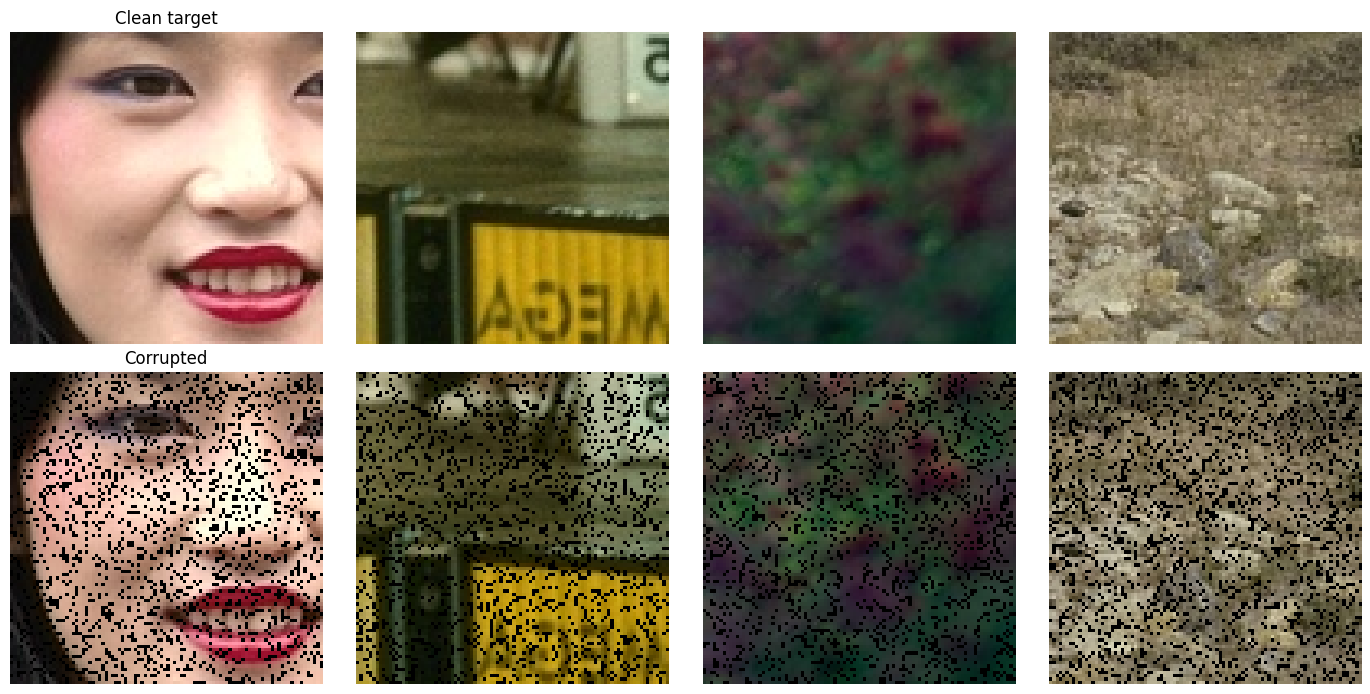

Pixel retention probability: 0.80 | Missing samples: 20%
Train batches: 50 | Validation images: 100
Independent test set: not available in this dataset package


In [ ]:
#@title Load dataset and visualize samples
data_path = '/content/BSDS500'
train_loader, val_loader, test_loader = load_data(data_path, batch_size=BATCH_SIZE)

x, y = next(iter(train_loader))
num_imgs = min(4, x.size(0))
fig, axs = plt.subplots(2, num_imgs, figsize=(14, 7))
for i in range(num_imgs):
    show_tensor(x[i], axs[0, i], 'Clean target' if i == 0 else None)
    show_tensor(y[i], axs[1, i], 'Corrupted' if i == 0 else None)
plt.tight_layout()
plt.show()

print(f'Pixel retention probability: {KEEP_PROBABILITY:.2f} | Missing samples: {(1-KEEP_PROBABILITY)*100:.0f}%')
print('Train batches:', len(train_loader), '| Validation images:', len(val_loader))
print('Independent test set:', 'available' if test_loader is not None else 'not available in this dataset package')


## 6.2 Corrupted-Input Baseline Evaluation

In [ ]:
#@title Corrupted-input baseline evaluation
def evaluate(loader, model=None):
    loss_m, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

    if model is not None:
        model.eval()

    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            pred = y if model is None else model(y)
            if cost_function == 'RMSE':
              loss = torch.sqrt(criterion(pred,x))
            else:
              loss = criterion(pred, x)
            psnr_val, ssim_val = compute_metrics(pred, x)

            n = x.size(0)
            loss_m.update(loss.item(), n)
            psnr_m.update(psnr_val, n)
            ssim_m.update(ssim_val, n)

    return {'loss': loss_m.avg, 'psnr': psnr_m.avg, 'ssim': ssim_m.avg}

# Baseline before training (validation)
baseline_pre = evaluate(val_loader, model=None)
print(f"Corrupted-input validation baseline | PSNR {baseline_pre['psnr']:.2f} dB | SSIM {baseline_pre['ssim']:.3f}")


Corrupted-input validation baseline | PSNR 13.54 dB | SSIM 0.278


# 7. Training

## 7.1 Training Loop

In [ ]:
#@title Training process with validation and best-model checkpoint
count = 0
history = {
    'train_loss': [], 'train_psnr': [], 'train_ssim': [],
    'val_loss': [], 'val_psnr': [], 'val_ssim': [], 'learning_rate': []
}

best_val_psnr = -float('inf')
best_state = None

for epoch in range(EPOCHS):
    count+=1

    if count<patience:
      losses, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()
      val_losses, val_psnr_m, val_ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

      model.train()
      for x, y in train_loader:
          x = x.to(device, non_blocking=True)
          y = y.to(device, non_blocking=True)

          optimizer.zero_grad(set_to_none=True)
          x_hat = model(y)
          if cost_function == 'Cross-Entropy':
            loss = criterion(x_hat.clamp(0.0, 1.0), x)
          else:
            loss = criterion(x_hat, x)
          loss.backward()
          optimizer.step()

          with torch.no_grad():
              psnr_val, ssim_val = compute_metrics(x_hat, x)

          n = x.size(0)
          losses.update(loss.item(), n)
          psnr_m.update(psnr_val, n)
          ssim_m.update(ssim_val, n)

      model.eval()
      with torch.inference_mode():
          for x, y in val_loader:
              x = x.to(device, non_blocking=True)
              y = y.to(device, non_blocking=True)
              x_hat = model(y)

              if cost_function == 'Cross-Entropy':
                loss = criterion(x_hat.clamp(0.0, 1.0), x)
              else:
                loss = criterion(x_hat, x)
              psnr_val, ssim_val = compute_metrics(x_hat, x)

              n = x.size(0)
              val_losses.update(loss.item(), n)
              val_psnr_m.update(psnr_val, n)
              val_ssim_m.update(ssim_val, n)

      current_lr = optimizer.param_groups[0]['lr']
      history['learning_rate'].append(current_lr)
      history['train_loss'].append(losses.avg)
      history['train_psnr'].append(psnr_m.avg)
      history['train_ssim'].append(ssim_m.avg)
      history['val_loss'].append(val_losses.avg)
      history['val_psnr'].append(val_psnr_m.avg)
      history['val_ssim'].append(val_ssim_m.avg)

      if scheduler is not None:   # use_cosine_scheduler = False -> constant LR
          scheduler.step()

      if val_psnr_m.avg > best_val_psnr:
          count=0
          best_val_psnr = val_psnr_m.avg
          best_state = copy.deepcopy(model.state_dict())
          torch.save(best_state, CHECKPOINT_PATH)
          print(
          f'New best PSNR at Epoch {epoch+1:03d}/{EPOCHS} | '
          f'LR {current_lr:.6f} | '
          f'Loss {losses.avg:.7f} | PSNR {psnr_m.avg:.2f} | SSIM {ssim_m.avg:.3f} | '
          f'Val Loss {val_losses.avg:.7f} | Val PSNR {val_psnr_m.avg:.2f} | Val SSIM {val_ssim_m.avg:.3f}'
          )
    else:
      print(f"There wasn't a better value after {count} epochs, stopping training")
      break

model.load_state_dict(best_state)
print(f'Best validation PSNR: {best_val_psnr:.2f} dB')
print('Best checkpoint:', CHECKPOINT_PATH)

New best PSNR at Epoch 001/300 | LR 0.002000 | Loss 0.0355754 | PSNR 23.25 | SSIM 0.628 | Val Loss 0.0138024 | Val PSNR 28.14 | Val SSIM 0.825
New best PSNR at Epoch 003/300 | LR 0.002000 | Loss 0.0101301 | PSNR 30.18 | SSIM 0.874 | Val Loss 0.0084818 | Val PSNR 31.75 | Val SSIM 0.920
New best PSNR at Epoch 004/300 | LR 0.002000 | Loss 0.0083631 | PSNR 31.64 | SSIM 0.908 | Val Loss 0.0076987 | Val PSNR 32.54 | Val SSIM 0.935
New best PSNR at Epoch 005/300 | LR 0.001999 | Loss 0.0079742 | PSNR 32.10 | SSIM 0.915 | Val Loss 0.0072923 | Val PSNR 33.06 | Val SSIM 0.939
New best PSNR at Epoch 006/300 | LR 0.001999 | Loss 0.0071885 | PSNR 32.80 | SSIM 0.930 | Val Loss 0.0073144 | Val PSNR 33.08 | Val SSIM 0.938
New best PSNR at Epoch 007/300 | LR 0.001998 | Loss 0.0070400 | PSNR 33.02 | SSIM 0.933 | Val Loss 0.0067565 | Val PSNR 33.62 | Val SSIM 0.948
New best PSNR at Epoch 010/300 | LR 0.001996 | Loss 0.0066142 | PSNR 33.72 | SSIM 0.938 | Val Loss 0.0061482 | Val PSNR 34.24 | Val SSIM 0.959

## 7.2 Training Curves

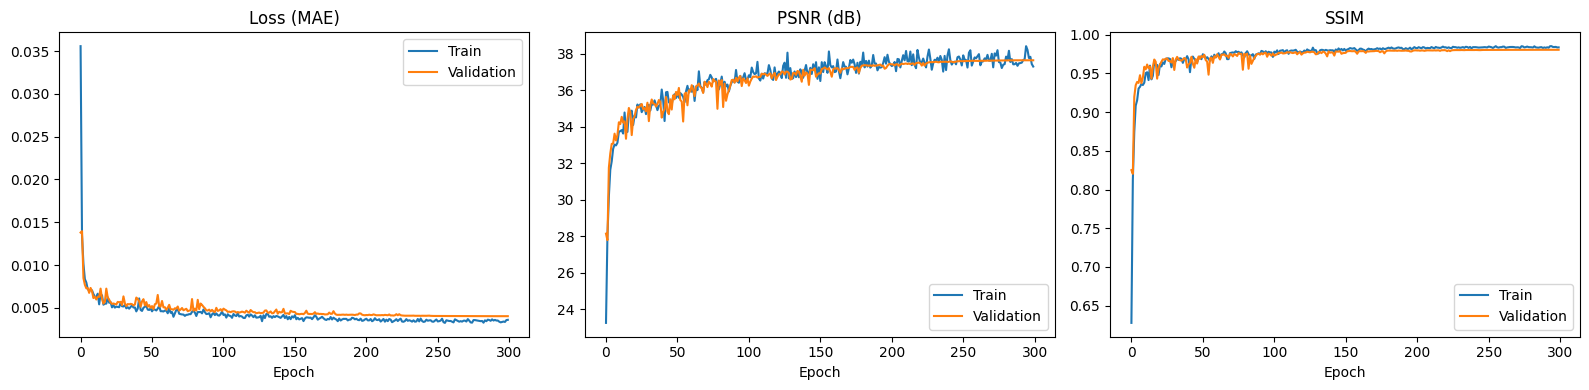

In [ ]:
#@title Training curves
fig, axs = plt.subplots(1, 3, figsize=(16, 4))

axs[0].plot(history['train_loss'], label='Train')
axs[0].plot(history['val_loss'], label='Validation')
axs[0].set_title(f'Loss ({cost_function})')
axs[0].set_xlabel('Epoch')
axs[0].legend()

axs[1].plot(history['train_psnr'], label='Train')
axs[1].plot(history['val_psnr'], label='Validation')
axs[1].set_title('PSNR (dB)')
axs[1].set_xlabel('Epoch')
axs[1].legend()

axs[2].plot(history['train_ssim'], label='Train')
axs[2].plot(history['val_ssim'], label='Validation')
axs[2].set_title('SSIM')
axs[2].set_xlabel('Epoch')
axs[2].legend()

plt.tight_layout()
plt.show()


## 7.3 Learning Rate Schedule

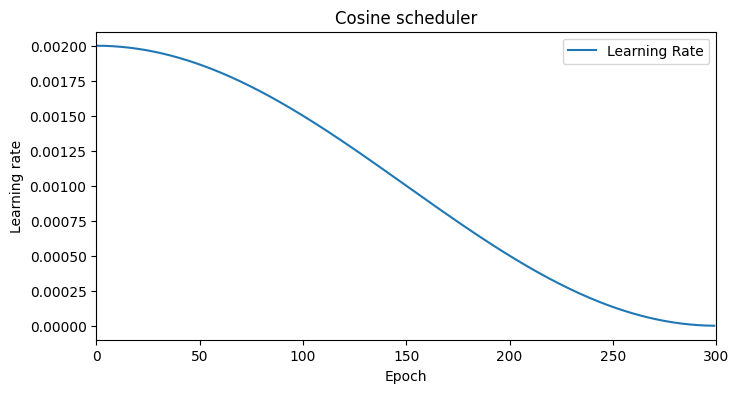

In [ ]:
#@title Learning rate schedule

fig, axs = plt.subplots(1, 1, figsize=(8, 4))

lrs = history['learning_rate']
axs.plot(lrs, label='Learning Rate')

axs.set_xlim(0, EPOCHS)
axs.set_title('Cosine scheduler' if use_cosine_scheduler else 'Learning rate (constant, no scheduler)')
axs.set_xlabel('Epoch')
axs.set_ylabel('Learning rate')
axs.legend()
plt.show()

# 8. Evaluation

## 8.1 Baseline vs Restored Image

In [ ]:
#@title Baseline vs restored-image evaluation
def evaluate(loader, model=None):
    loss_m, psnr_m, ssim_m = AverageMeter(), AverageMeter(), AverageMeter()

    if model is not None:
        model.eval()

    with torch.inference_mode():
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            pred = y if model is None else model(y)
            loss = criterion(pred, x)
            psnr_val, ssim_val = compute_metrics(pred, x)

            n = x.size(0)
            loss_m.update(loss.item(), n)
            psnr_m.update(psnr_val, n)
            ssim_m.update(ssim_val, n)

    return {'loss': loss_m.avg, 'psnr': psnr_m.avg, 'ssim': ssim_m.avg}

final_loader = test_loader if test_loader is not None else val_loader
final_split = 'TEST' if test_loader is not None else 'VALIDATION (no independent test folder found)'

baseline = evaluate(final_loader, model=None)
restored = evaluate(final_loader, model=model)

print(final_split)
print(f"Input baseline  | Loss {baseline['loss']:.7f} | PSNR {baseline['psnr']:.2f} dB | SSIM {baseline['ssim']:.3f}")
print(f"Restored model  | Loss {restored['loss']:.7f} | PSNR {restored['psnr']:.2f} dB | SSIM {restored['ssim']:.3f}")
print(f"PSNR gain       | {restored['psnr'] - baseline['psnr']:+.2f} dB")


VALIDATION (no independent test folder found)
Input baseline  | Loss 0.0851477 | PSNR 13.54 dB | SSIM 0.278
Restored model  | Loss 0.0040325 | PSNR 37.64 dB | SSIM 0.981
PSNR gain       | +24.11 dB


## 8.2 Visual Inference

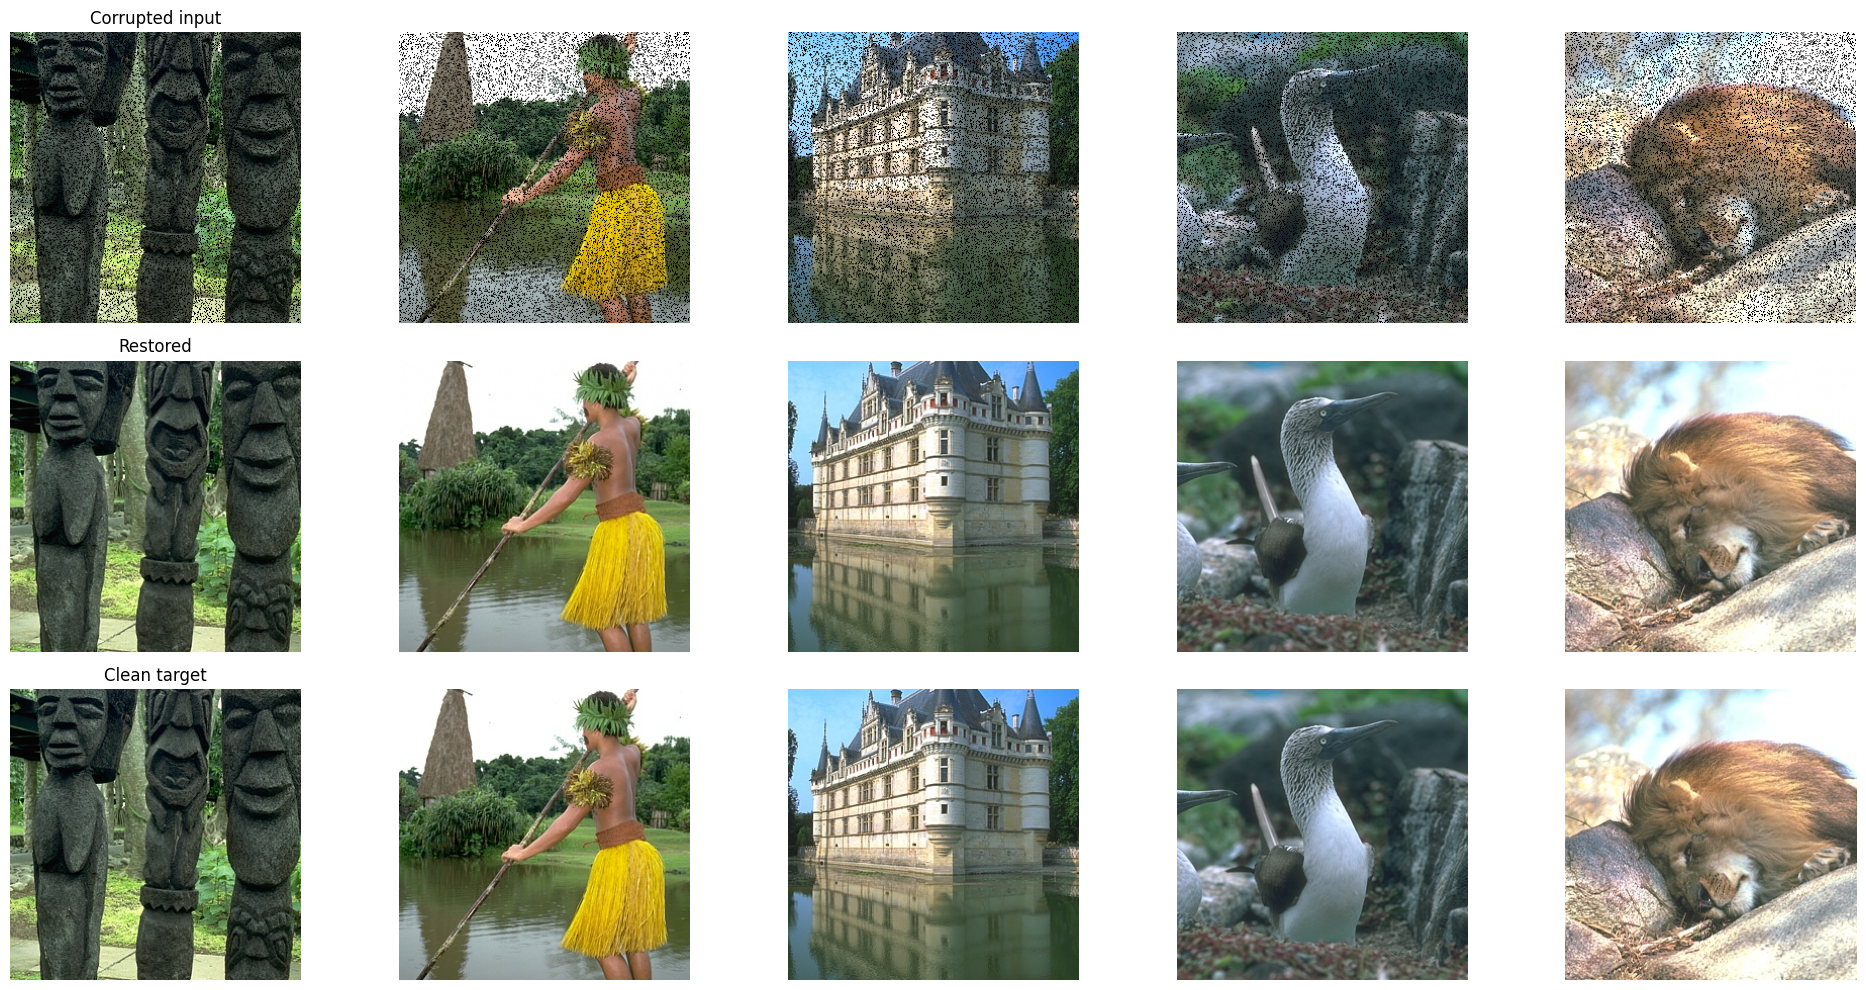

In [ ]:
#@title Visual inference
loader = test_loader if test_loader is not None else val_loader
num_images = min(5, len(loader))
fig, axs = plt.subplots(3, num_images, figsize=(4*num_images, 10))
axs = np.array(axs).reshape(3, num_images)

model.eval()
with torch.inference_mode():
    for i, (x, y) in enumerate(loader):
        if i >= num_images:
            break
        pred = model(y.to(device)).cpu().clamp(0, 1)
        show_tensor(y[0], axs[0, i], 'Corrupted input' if i == 0 else None)
        show_tensor(pred[0], axs[1, i], 'Restored' if i == 0 else None)
        show_tensor(x[0], axs[2, i], 'Clean target' if i == 0 else None)

plt.tight_layout()
plt.show()


## 8.3 Image Visualization With Absolute Errors

In [ ]:
#@title Image visualization with absolute errors
from mpl_toolkits.axes_grid1 import make_axes_locatable

val_samples = list(val_loader)
num_val_images = len(val_samples)

def patch(image_index, y_start, x_start, size):
    x_val, y_val = val_samples[image_index]
    model.eval()
    with torch.inference_mode():
        pred_val = model(y_val.to(device)).cpu().clamp(0, 1)

    clean_np = (x_val[0].permute(1, 2, 0).numpy() * 255.0).astype(np.float32)
    corr_np = (y_val[0].permute(1, 2, 0).numpy() * 255.0).astype(np.float32)
    rest_np = (pred_val[0].permute(1, 2, 0).numpy() * 255.0).astype(np.float32)

    H, W, _ = clean_np.shape

    y_end = min(y_start + size, H)
    x_end = min(x_start + size, W)

    p_clean = clean_np[y_start:y_end, x_start:x_end] / 255.0
    p_corr = corr_np[y_start:y_end, x_start:x_end] / 255.0
    p_rest = rest_np[y_start:y_end, x_start:x_end] / 255.0

    p_error = np.abs(p_clean - p_rest).mean(axis=2)

    fig, axs = plt.subplots(2, 4, figsize=(16, 8))

    axs[0, 0].imshow(clean_np / 255.0)
    axs[0, 0].set_title("Clean Target")
    rect = plt.Rectangle((x_start, y_start), size, size, fill=False, color='red', linewidth=2)
    axs[0, 0].add_patch(rect)
    axs[0, 0].axis('off')

    axs[0, 1].imshow(corr_np / 255.0)
    axs[0, 1].set_title("Corrupted Input")
    rect2 = plt.Rectangle((x_start, y_start), size, size, fill=False, color='red', linewidth=2)
    axs[0, 1].add_patch(rect2)
    axs[0, 1].axis('off')

    axs[0, 2].imshow(rest_np / 255.0)
    axs[0, 2].set_title("Restored Model")
    rect3 = plt.Rectangle((x_start, y_start), size, size, fill=False, color='red', linewidth=2)
    axs[0, 2].add_patch(rect3)
    axs[0, 2].axis('off')

    axs[0, 3].axis('off')

    axs[1, 0].imshow(p_clean)
    axs[1, 0].set_title(f"Clean Target (Zoom {size}x{size})")
    axs[1, 0].axis('off')
    axs[1, 0].set_box_aspect(1)

    axs[1, 1].imshow(p_corr)
    axs[1, 1].set_title("Corrupted Patch")
    axs[1, 1].axis('off')
    axs[1, 1].set_box_aspect(1)

    axs[1, 2].imshow(p_rest)
    axs[1, 2].set_title("Restored Patch")
    axs[1, 2].axis('off')
    axs[1, 2].set_box_aspect(1)

    im_err = axs[1, 3].imshow(p_error, cmap='hot', vmin=0, vmax=50/255.0)
    axs[1, 3].set_title("Absolute Error (Patch)")
    axs[1, 3].axis('off')
    axs[1, 3].set_box_aspect(1)

    divider = make_axes_locatable(axs[1, 3])
    cax = divider.append_axes("right", size="5%", pad=0.1)
    fig.colorbar(im_err, cax=cax, label="Intensity Difference")

    plt.tight_layout()
    plt.show()

style = {'description_width': '120px'}
image_select = widgets.IntSlider(min=0, max=4, step=1, value=0, description='Image Index:', style=style)
size_select = widgets.SelectionSlider(options=[32, 64, 96], value=64, description='Patch size:', style=style)
y_slider = widgets.IntSlider(min=0, max=288-32, step=1, value=144-32, description='Height:', style=style)
x_slider = widgets.IntSlider(min=0, max=288-32, step=1, value=144-32, description='Width:', style=style)

def update_limits(*args):
    y_slider.max = 288 - size_select.value
    x_slider.max = 288 - size_select.value

size_select.observe(update_limits, 'value')

out_interact = widgets.interactive_output(patch, {
    'image_index': image_select,
    'y_start': y_slider,
    'x_start': x_slider,
    'size': size_select
})
display(widgets.VBox([image_select, size_select, y_slider, x_slider, out_interact]))

## 8.4 Clean Target Histograms

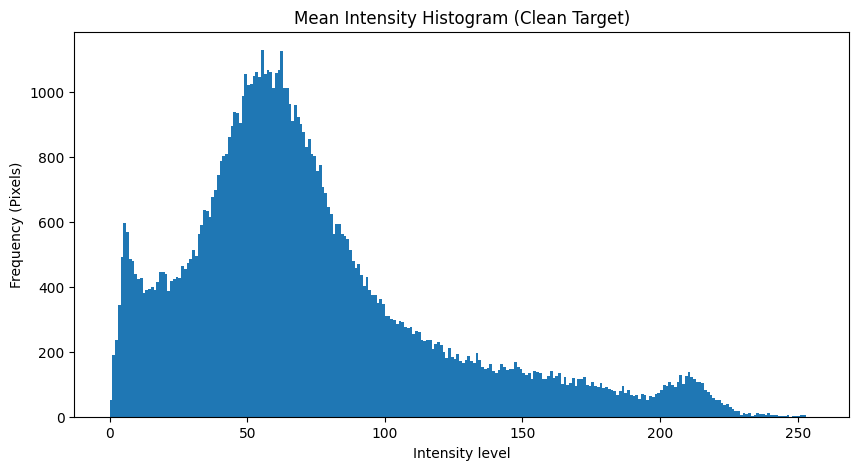

In [ ]:
#@title Clean Target histogram

x_batch, y_batch = next(iter(val_loader))
original_image = x_batch[0]
image_np = original_image.permute(1, 2, 0).cpu().numpy() * 255.0
image = image_np.mean(axis=2)

plt.figure(figsize=(10, 5))
plt.hist(image.ravel(), bins=256, range=[0, 256])
plt.xlabel("Intensity level")
plt.ylabel("Frequency (Pixels)")
plt.title("Mean Intensity Histogram (Clean Target)")
plt.show()

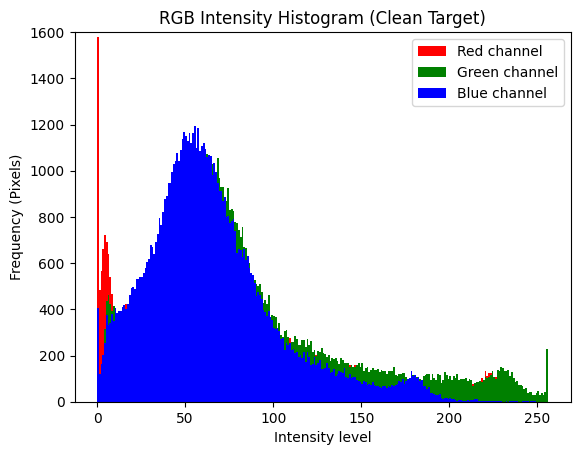

In [ ]:
#@title RGB histogram

plt.hist(image_np[:,:,0].ravel(), bins=256, range=[0,256], color="Red", label="Red channel")
plt.hist(image_np[:,:,1].ravel(), bins=256, range=[0,256], color="Green", label="Green channel")
plt.hist(image_np[:,:,2].ravel(), bins=256, range=[0,256], color="Blue", label="Blue channel")

plt.xlabel("Intensity level")
plt.ylabel("Frequency (Pixels)")
plt.title("RGB Intensity Histogram (Clean Target)")
plt.legend()
plt.ylim(0,1600)
plt.show()

## 8.5 Prediction Histograms

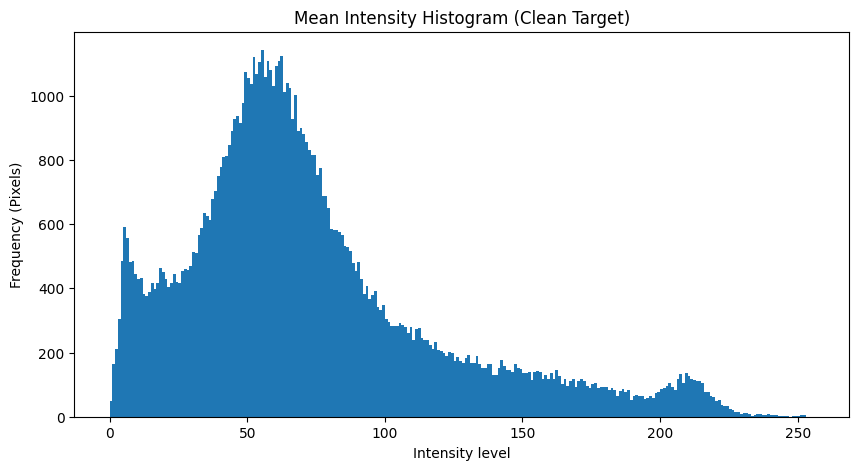

In [ ]:
#@title Mean intensity histogram (Prediction)

x_hat = model(y_batch.to(device))
prediction_np = x_hat[0].permute(1, 2, 0).cpu().detach().numpy() * 255.0
prediction = prediction_np.mean(axis=2)

plt.figure(figsize=(10, 5))
plt.hist(prediction.ravel(), bins=256, range=[0, 256])
plt.xlabel("Intensity level")
plt.ylabel("Frequency (Pixels)")
plt.title("Mean Intensity Histogram (Clean Target)")
plt.show()

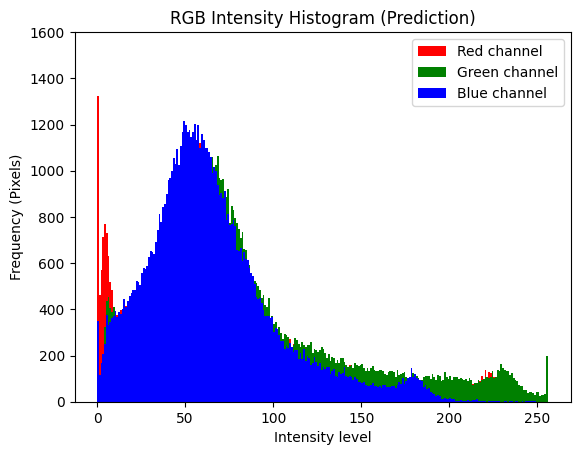

In [ ]:
#@title RGB histogram (Prediction)

plt.hist(prediction_np[:,:,0].ravel(), bins=256, range=[0,256], color="Red", label="Red channel")
plt.hist(prediction_np[:,:,1].ravel(), bins=256, range=[0,256], color="Green", label="Green channel")
plt.hist(prediction_np[:,:,2].ravel(), bins=256, range=[0,256], color="Blue", label="Blue channel")

plt.xlabel("Intensity level")
plt.ylabel("Frequency (Pixels)")
plt.title("RGB Intensity Histogram (Prediction)")
plt.ylim(0,1600)
plt.legend()
plt.show()

In [ ]:
#@title Visualization of the first image in the dataset

import numpy as np
import torch
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

model.eval()
device = next(model.parameters()).device

def show_sample(idx):
    clean_y, corrupted_y = val_samples[idx]
    with torch.no_grad():
        prediction = model(corrupted_y.to(device))

    image_np = np.clip(clean_y[0].permute(1, 2, 0).cpu().detach().numpy(), 0, 1)
    corrupted_np = np.clip(corrupted_y[0].permute(1, 2, 0).cpu().detach().numpy(), 0, 1)
    prediction_np = np.clip(prediction[0].permute(1, 2, 0).cpu().detach().numpy(), 0, 1)

    fig, axs = plt.subplots(1, 3, figsize=(14, 5))

    axs[0].imshow(image_np)
    axs[0].set_title("Clean Target")
    axs[0].axis('off')

    axs[1].imshow(corrupted_np)
    axs[1].set_title("Corrupted Input")
    axs[1].axis('off')

    axs[2].imshow(prediction_np)
    axs[2].set_title("Restored Model")
    axs[2].axis('off')

    plt.tight_layout()
    plt.show()

slider = widgets.IntSlider(
    value=0,
    min=0,
    max=3,
    step=1,
    description='Imagen:',
    continuous_update=False,
    layout=widgets.Layout(width='280px'),
    style={'description_width': 'initial', 'handle_color': '#38bdf8'}
)

out = widgets.interactive_output(show_sample, {'idx': slider})
display(widgets.HBox([slider], layout=widgets.Layout(justify_content='center')), out)

Output()

# 9. Run Tracking

What follows is a section for automatically saving and loading the data we collect from each run, storing the hyperparameters along with their respective results and plots. We do this to keep constant track, a history of the project's progress, all saved in a Drive. Pedro, this was made with AI so that it would look nicer, don't judge me UnU

## 9.1 Save Results

In [ ]:
#@title Save results to Google Drive (with description and button)
import csv, html, json, os, shutil
from datetime import datetime, timezone, timedelta
import numpy as np
from matplotlib.figure import Figure
from mpl_toolkits.axes_grid1 import make_axes_locatable
import ipywidgets as widgets
from IPython.display import display
from google.colab import drive

try:
    from zoneinfo import ZoneInfo
    BOGOTA = ZoneInfo('America/Bogota')
except Exception:
    BOGOTA = timezone(timedelta(hours=-5))  # Colombia does not use daylight saving time

drive.mount('/content/drive')

# Default values (can be changed in the fields below, without touching the code)
DEFAULT_NOTEBOOK_NAME = 'impaiting_pedro_marin'
DEFAULT_SOURCE_URL = 'https://github.com/Lerreto/Inpainting-Numerical-Project-2026/blob/pedro/impaiting_pedro_marin.ipynb'
_CANDIDATES = [
    '/content/drive/MyDrive/UIS/Semestre 4/Analisis Numerico/Backs',  # folder owner
    '/content/drive/MyDrive/Backs',                                    # teammate with direct access
]
DEFAULT_DRIVE_ROOT = next((p for p in _CANDIDATES if os.path.isdir(p)), _CANDIDATES[0])


def guardar_resultados(descripcion, notebook_name, drive_root, source_url):
    notebook_name = notebook_name.strip()
    drive_root = drive_root.strip().rstrip('/')
    if not notebook_name:
        raise ValueError('The notebook name cannot be empty.')
    if not drive_root.startswith('/content/drive/'):
        raise ValueError("The path must start with '/content/drive/' (for example '/content/drive/MyDrive/My_Folder').")
    if not os.path.isdir('/content/drive/MyDrive') and not drive_root.startswith('/content/drive/Shareddrives'):
        raise RuntimeError('Drive is not mounted. Run the cell again.')

    now = datetime.now(BOGOTA)  # Colombia time
    _modelo = globals().get('model_name', type(model).__name__)
    run_name = (f"{now:%Y%m%d_%H%M%S}_{_modelo}_{optimizer_name}_{cost_function}"
                f"_lr{learning_rate}_bf{base_filter}")
    save_dir = os.path.join(drive_root, notebook_name, run_name)
    os.makedirs(save_dir, exist_ok=True)
    print('Saving to:', save_dir)

    # ---- Per-epoch history ----
    keys = list(history.keys())
    n_epochs_run = len(history['train_loss'])
    with open(os.path.join(save_dir, 'history.csv'), 'w', newline='') as f:
        w = csv.writer(f)
        w.writerow(['epoch'] + keys)
        for i in range(n_epochs_run):
            w.writerow([i + 1] + [history[k][i] for k in keys])

    # ---- Best epoch (same line printed during training) ----
    best_idx = int(np.argmax(history['val_psnr']))
    best_line = (
        f"New best PSNR at Epoch {best_idx + 1:03d}/{EPOCHS} | "
        f"Loss {history['train_loss'][best_idx]:.7f} | PSNR {history['train_psnr'][best_idx]:.2f} | "
        f"SSIM {history['train_ssim'][best_idx]:.3f} | "
        f"Val Loss {history['val_loss'][best_idx]:.7f} | "
        f"Val PSNR {history['val_psnr'][best_idx]:.2f} | Val SSIM {history['val_ssim'][best_idx]:.3f}"
    )
    best_summary = f"Best validation PSNR: {best_val_psnr:.2f} dB"

    # ---- Hyperparameters ----
    hiperparametros = {
        'notebook': notebook_name,
        'fuente': source_url.strip(),
        'descripcion': descripcion.strip(),
        'fecha_corrida': now.isoformat(timespec='seconds'),  # includes the time zone (-05:00)
        'dispositivo': str(device),
        'semilla': SEED,
        'dataset': {'nombre': 'BSDS500', 'recorte_train': 96, 'recorte_val': 288, 'batch_size': BATCH_SIZE},
        'corrupcion': {'prob_retencion': KEEP_PROBABILITY,
                       'fraccion_faltante': round(1 - KEEP_PROBABILITY, 4),
                       'mascaras_train': 'online',
                       'mascaras_eval': 'deterministic'},
        'modelo': {**globals().get('model_config', {'nombre': type(model).__name__}),
                   'parametros_entrenables': n_params},
        'entrenamiento': {'epocas_max': EPOCHS, 'epocas_ejecutadas': n_epochs_run,
                          'patience': patience, 'optimizador': optimizer_name,
                          'learning_rate': learning_rate,
                          'weight_decay': optimizer.param_groups[0]['weight_decay'],
                          'funcion_costo': cost_function,
                          'scheduler': 'CosineAnnealingLR' if use_cosine_scheduler else 'none',
                          'T_max': EPOCHS if use_cosine_scheduler else None},
    }
    with open(os.path.join(save_dir, 'hiperparametros.json'), 'w', encoding='utf-8') as f:
        json.dump(hiperparametros, f, indent=2, ensure_ascii=False)

    # ---- Metrics ----
    metricas = {
        'mejor_epoca': best_idx + 1,
        'mejor_val_psnr_db': best_val_psnr,
        'evaluacion_split': final_split,
        'baseline': baseline,
        'restaurado': restored,
        'ganancia_psnr_db': restored['psnr'] - baseline['psnr'],
    }
    with open(os.path.join(save_dir, 'metricas.json'), 'w', encoding='utf-8') as f:
        json.dump(metricas, f, indent=2, ensure_ascii=False)

    resumen = [
        f"Description: {descripcion.strip() or '(no description)'}",
        '',
        best_line,
        best_summary,
        '',
        f"Baseline (corrupted input) | PSNR {baseline['psnr']:.2f} dB | SSIM {baseline['ssim']:.3f}",
        f"Restored                   | PSNR {restored['psnr']:.2f} dB | SSIM {restored['ssim']:.3f}",
        f"PSNR gain                  | {restored['psnr'] - baseline['psnr']:+.2f} dB",
        f"Evaluated on: {final_split}",
    ]
    with open(os.path.join(save_dir, 'resumen.txt'), 'w', encoding='utf-8') as f:
        f.write('\n'.join(resumen) + '\n')

    # ---- Best checkpoint ----
    shutil.copy(CHECKPOINT_PATH, os.path.join(save_dir, 'mejor_modelo.pt'))

    # Figures are created with Figure() (without pyplot) so Colab does not display them on screen.

    # ---- Figure 1: training curves ----
    fig = Figure(figsize=(16, 4))
    axs = fig.subplots(1, 3)
    for ax, m, t in zip(axs, ['loss', 'psnr', 'ssim'], [f'Loss ({cost_function})', 'PSNR (dB)', 'SSIM']):
        ax.plot(history[f'train_{m}'], label='Train')
        ax.plot(history[f'val_{m}'], label='Validation')
        ax.axvline(best_idx, color='gray', linestyle='--', label='Best epoch')
        ax.set_title(t)
        ax.set_xlabel('Epoch')
        ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(save_dir, 'fig_curvas_entrenamiento.png'), dpi=150, bbox_inches='tight')

    # ---- Figure 2: metric comparison, baseline vs restored ----
    labels = ['Corrupted input', 'Restored']
    fig = Figure(figsize=(10, 4))
    axs = fig.subplots(1, 2)
    bars = axs[0].bar(labels, [baseline['psnr'], restored['psnr']], color=['gray', 'tab:blue'])
    axs[0].bar_label(bars, fmt='%.2f')
    axs[0].set_title('PSNR (dB)')
    bars = axs[1].bar(labels, [baseline['ssim'], restored['ssim']], color=['gray', 'tab:blue'])
    axs[1].bar_label(bars, fmt='%.3f')
    axs[1].set_title('SSIM')
    fig.tight_layout()
    fig.savefig(os.path.join(save_dir, 'fig_comparacion_metricas.png'), dpi=150, bbox_inches='tight')

    # ---- Figure 3: visual comparison (input, restored, target) ----
    final_loader = test_loader if test_loader is not None else val_loader
    num_show = min(3, len(final_loader))
    fig = Figure(figsize=(4 * num_show, 10))
    axs = fig.subplots(3, num_show, squeeze=False)
    model.eval()
    with torch.inference_mode():
        for i, (x, y) in enumerate(final_loader):
            if i >= num_show:
                break
            pred = model(y.to(device)).cpu().clamp(0, 1)
            show_tensor(y[0], axs[0, i], 'Corrupted input' if i == 0 else None)
            show_tensor(pred[0], axs[1, i], 'Restored' if i == 0 else None)
            show_tensor(x[0], axs[2, i], 'Clean target' if i == 0 else None)
    fig.tight_layout()
    fig.savefig(os.path.join(save_dir, 'fig_comparacion_visual.png'), dpi=150, bbox_inches='tight')

    # ---- Figure 4: learning rate schedule ----
    fig = Figure(figsize=(8, 4))
    ax = fig.subplots()
    ax.plot(history['learning_rate'], label='Learning Rate')
    ax.set_xlim(0, EPOCHS)
    ax.set_title('Cosine scheduler' if use_cosine_scheduler else 'Learning rate (constant, no scheduler)')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Learning rate')
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(save_dir, 'fig_lr_schedule.png'), dpi=150, bbox_inches='tight')

    # ---- Figure 5: mean and RGB histograms of the first validation image ----
    x_hist, y_hist = next(iter(val_loader))
    with torch.inference_mode():
        pred_hist = model(y_hist.to(device))
    fig = Figure(figsize=(16, 9))
    axs = fig.subplots(2, 2)
    for row, (tensor, name) in enumerate([(x_hist[0], 'Clean Target'), (pred_hist[0], 'Prediction')]):
        img_np = tensor.permute(1, 2, 0).cpu().numpy() * 255.0
        axs[row, 0].hist(img_np.mean(axis=2).ravel(), bins=256, range=[0, 256])
        axs[row, 0].set_title(f'Mean Intensity Histogram ({name})')
        for ch, color in enumerate(['Red', 'Green', 'Blue']):
            axs[row, 1].hist(img_np[:, :, ch].ravel(), bins=256, range=[0, 256], color=color, label=f'{color} channel')
        axs[row, 1].set_title(f'RGB Intensity Histogram ({name})')
        axs[row, 1].set_ylim(0, 1600)
        axs[row, 1].legend()
        for ax in axs[row]:
            ax.set_xlabel('Intensity level')
            ax.set_ylabel('Frequency (Pixels)')
    fig.tight_layout()
    fig.savefig(os.path.join(save_dir, 'fig_histograms.png'), dpi=150, bbox_inches='tight')

    # ---- Figure 6: absolute error per image (same layout as the interactive cell) ----
    # Uses the patch selected in the sliders; if that cell was not run, it uses their default values.
    size = size_select.value if 'size_select' in globals() else 64
    y0 = y_slider.value if 'y_slider' in globals() else 144 - 32
    x0 = x_slider.value if 'x_slider' in globals() else 144 - 32
    error_files = []
    model.eval()
    with torch.inference_mode():
        for i, (x_val, y_val) in enumerate(val_loader):
            if i >= 5:  # same images the "Image Index" slider can select
                break
            pred_val = model(y_val.to(device)).cpu().clamp(0, 1)
            full = [t[0].permute(1, 2, 0).numpy() for t in (x_val, y_val, pred_val)]
            crops = [a[y0:y0 + size, x0:x0 + size] for a in full]
            p_error = np.abs(crops[0] - crops[2]).mean(axis=2)
            fig = Figure(figsize=(16, 8))
            axs = fig.subplots(2, 4)
            for ax, img, t in zip(axs[0], full, ['Clean Target', 'Corrupted Input', 'Restored Model']):
                ax.imshow(img)
                ax.set_title(t)
                ax.add_patch(plt.Rectangle((x0, y0), size, size, fill=False, color='red', linewidth=2))
                ax.axis('off')
            axs[0, 3].axis('off')
            for ax, img, t in zip(axs[1], crops, [f'Clean Target (Zoom {size}x{size})', 'Corrupted Patch', 'Restored Patch']):
                ax.imshow(img)
                ax.set_title(t)
                ax.axis('off')
                ax.set_box_aspect(1)
            im_err = axs[1, 3].imshow(p_error, cmap='magma', vmin=0, vmax=50 / 255.0)
            axs[1, 3].set_title('Absolute Error (Patch)')
            axs[1, 3].axis('off')
            axs[1, 3].set_box_aspect(1)
            cax = make_axes_locatable(axs[1, 3]).append_axes('right', size='5%', pad=0.1)
            fig.colorbar(im_err, cax=cax, label='Intensity Difference')
            fig.tight_layout()
            error_files.append(f'fig_error_image_{i}.png')
            fig.savefig(os.path.join(save_dir, error_files[-1]), dpi=100, bbox_inches='tight')

    os.sync()  # tries to force the write before finishing
    esperados = ['hiperparametros.json', 'metricas.json', 'resumen.txt', 'history.csv', 'mejor_modelo.pt',
                 'fig_curvas_entrenamiento.png', 'fig_comparacion_metricas.png', 'fig_comparacion_visual.png',
                 'fig_lr_schedule.png', 'fig_histograms.png'] + error_files
    faltan = [n for n in esperados if not os.path.exists(os.path.join(save_dir, n))]
    if faltan:
        print('WARNING, missing files:', faltan)
    print('Saved files:', sorted(os.listdir(save_dir)))
    print(best_line)
    print(best_summary)
    return save_dir, now


# ---- Interface: fields + button + confirmation message ----
_style = {'description_width': '95px'}
_wide = widgets.Layout(width='760px')
w_nb = widgets.Text(value=DEFAULT_NOTEBOOK_NAME, description='Notebook:', style=_style, layout=_wide)
w_root = widgets.Text(value=DEFAULT_DRIVE_ROOT, description='Drive path:', style=_style, layout=_wide)
w_src = widgets.Text(value=DEFAULT_SOURCE_URL, description='Source:', style=_style, layout=_wide)
w_desc = widgets.Textarea(placeholder='Write a description of this run here (optional)',
                          description='Description:', style=_style,
                          layout=widgets.Layout(width='760px', height='90px'))
btn = widgets.Button(description='Save to Drive', button_style='success', icon='save')
status = widgets.HTML(value='')
out = widgets.Output()

_BOX = 'padding:8px 12px;border-radius:6px;border:1px solid {c};color:{c};margin:6px 0;max-width:740px'


def _on_click(_):
    out.clear_output()
    btn.disabled = True
    status.value = '<div style="opacity:.8;margin:6px 0">⏳ Saving…</div>'
    try:
        with out:
            save_dir, ts = guardar_resultados(w_desc.value, w_nb.value, w_root.value, w_src.value)
        status.value = (f'<div style="{_BOX.format(c="#3fb950")}">✅ Saved at {ts:%H:%M:%S} '
                        f'(Colombia time) to <code>{html.escape(save_dir)}</code></div>')
    except Exception as e:
        status.value = (f'<div style="{_BOX.format(c="#f85149")}">❌ Error while saving: '
                        f'{html.escape(repr(e))}</div>')
    finally:
        btn.disabled = False


def _clear_status(change):
    # Changing any field clears the "saved" message.
    status.value = ''
    out.clear_output()


for _w in (w_desc, w_nb, w_root, w_src):
    _w.observe(_clear_status, names='value')

btn.on_click(_on_click)
display(widgets.VBox([w_nb, w_root, w_src, w_desc, btn, status, out]))

Mounted at /content/drive


## 9.2 View Saved Runs

In [ ]:
#@title Saved runs viewer
import glob, html, json, os
from datetime import datetime, timezone, timedelta
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from google.colab import drive

try:
    from zoneinfo import ZoneInfo
    BOGOTA = ZoneInfo('America/Bogota')
except Exception:
    BOGOTA = timezone(timedelta(hours=-5))  # Colombia does not use daylight saving time

drive.mount('/content/drive')

_CANDIDATES = [
    '/content/drive/MyDrive/UIS/Semestre 4/Analisis Numerico/Backs',
    '/content/drive/MyDrive/Backs',
]
DRIVE_ROOT = next((p for p in _CANDIDATES if os.path.isdir(p)), _CANDIDATES[0])

FIG_FILES = [('fig_curvas_entrenamiento.png', 'Training curves'),
             ('fig_comparacion_metricas.png', 'Corrupted input vs. restored'),
             ('fig_comparacion_visual.png', 'Visual comparison')]
# Added later: older runs do not have these figures, so they are simply not shown.
OPTIONAL_FIG_FILES = [('fig_lr_schedule.png', 'Learning rate schedule'),
                      ('fig_histograms.png', 'Intensity histograms (first validation image)')]

# Styles that work in light and dark themes
CSS = """<style>
.rv{font-size:14px;line-height:1.45}
.rv h3{margin:4px 0 2px 0}
.rv a{color:inherit;text-decoration:underline}
.rv .sub{opacity:.75;margin:0 0 10px 0}
.rv-card{display:inline-block;min-width:140px;margin:4px 10px 4px 0;padding:10px 14px;border:1px solid rgba(127,127,127,.35);border-radius:8px;background:rgba(127,127,127,.10);vertical-align:top}
.rv-card .v{font-size:22px;font-weight:600;line-height:1.25}
.rv-card .l{font-size:12px;opacity:.7}
.rv-sec{display:inline-block;vertical-align:top;margin:6px 18px 10px 0;min-width:270px}
.rv-sec h4{margin:0 0 6px 0;font-size:14px}
.rv-t{border-collapse:collapse;font-size:13px}
.rv-t td,.rv-t th{padding:3px 12px 3px 0;border-bottom:1px solid rgba(127,127,127,.25);text-align:left}
.rv-t td:first-child{opacity:.75}
.rv-good{color:#3fb950}
.rv-pre{margin:8px 0;padding:8px 12px;border-radius:6px;background:rgba(127,127,127,.10);font-size:12.5px;white-space:pre-wrap}
.rv-warn{padding:8px 12px;border-radius:6px;border:1px solid #d29922;color:#d29922;margin:6px 0}
</style>"""


def _fecha_dt(hp):
    """Run date as a timezone-aware datetime. Older runs were saved in UTC without a time zone."""
    dt = datetime.fromisoformat(hp['fecha_corrida'])
    if dt.tzinfo is None:
        dt = dt.replace(tzinfo=timezone.utc)
    return dt


def fmt_fecha(hp):
    try:
        return _fecha_dt(hp).astimezone(BOGOTA).strftime('%d/%m/%Y %H:%M:%S')
    except Exception:
        return str(hp.get('fecha_corrida', ''))


def fmt_val(v):
    if isinstance(v, bool):
        return str(v)
    if isinstance(v, int):
        return f'{v:,}'
    if isinstance(v, float):
        return f'{v:g}'
    return html.escape(str(v))


def find_runs():
    runs = []
    for p in glob.glob(os.path.join(DRIVE_ROOT, '*', '*', 'hiperparametros.json')):
        run_dir = os.path.dirname(p)
        try:
            with open(p, encoding='utf-8') as f:
                hp = json.load(f)
            with open(os.path.join(run_dir, 'metricas.json'), encoding='utf-8') as f:
                me = json.load(f)
            key = _fecha_dt(hp)
        except Exception:
            continue  # incomplete run, or one Drive is still syncing
        runs.append({'dir': run_dir, 'notebook': os.path.basename(os.path.dirname(run_dir)),
                     'name': os.path.basename(run_dir), 'hp': hp, 'me': me, 'key': key})
    runs.sort(key=lambda r: r['key'], reverse=True)  # most recent first
    return runs


def run_label(r):
    desc = r['hp'].get('descripcion') or 'no description'
    if len(desc) > 45:
        desc = desc[:42] + '...'
    modelo = r['hp'].get('modelo', {}).get('nombre', '')
    return f"{fmt_fecha(r['hp'])}  ·  {modelo}  ·  {r['me']['mejor_val_psnr_db']:.2f} dB  ·  {desc}"


# ---------- Content of each tab ----------
def resumen_html(r):
    hp, me = r['hp'], r['me']
    ent, mod = hp['entrenamiento'], hp['modelo']
    base, rest = me['baseline'], me['restaurado']
    desc = html.escape(hp.get('descripcion') or '(no description)')
    src = html.escape(hp.get('fuente', ''))
    cards = [
        (f"{me['mejor_val_psnr_db']:.2f} dB", 'Best PSNR (validation)', ''),
        (f"{rest['ssim']:.3f}", 'Restored SSIM', ''),
        (f"{me['ganancia_psnr_db']:+.2f} dB", 'Gain vs. corrupted input', 'rv-good'),
        (f"{me['mejor_epoca']} / {ent['epocas_max']}", 'Best epoch', ''),
        (f"{mod['parametros_entrenables']:,}", 'Parameters', ''),
    ]
    cards_html = ''.join(f'<div class="rv-card"><div class="v {c}">{v}</div><div class="l">{l}</div></div>'
                         for v, l, c in cards)
    try:
        with open(os.path.join(r['dir'], 'resumen.txt'), encoding='utf-8') as f:
            lines = f.read().splitlines()
        # The description and baseline lines are skipped (already shown above and in the table).
        best = '\n'.join(l for l in lines[2:4] if l.strip())
    except Exception:
        best = ''
    return (CSS + f'<div class="rv"><h3>{desc}</h3>'
            f'<p class="sub">{fmt_fecha(hp)} (Colombia time) · {html.escape(r["notebook"])} · '
            f'<a href="{src}" target="_blank">source</a></p>'
            f'{cards_html}'
            '<table class="rv-t" style="margin:10px 0"><tr><th></th><th>PSNR</th><th>SSIM</th></tr>'
            f'<tr><td>Corrupted input</td><td>{base["psnr"]:.2f} dB</td><td>{base["ssim"]:.3f}</td></tr>'
            f'<tr><td>Restored</td><td>{rest["psnr"]:.2f} dB</td><td>{rest["ssim"]:.3f}</td></tr></table>'
            f'<div class="rv-pre">{html.escape(best)}</div>'
            f'<div class="sub">Evaluated on: {html.escape(str(me.get("evaluacion_split", "")))}</div></div>')


def hiperparametros_html(r):
    hp = r['hp']
    general = [(k, v) for k, v in hp.items() if not isinstance(v, dict) and k not in ('fuente', 'descripcion')]
    secciones = [('general', general)] + [(k, list(v.items())) for k, v in hp.items() if isinstance(v, dict)]
    partes = []
    for titulo, items in secciones:
        filas = ''.join(f'<tr><td>{html.escape(k.replace("_", " "))}</td><td>{fmt_val(v)}</td></tr>'
                        for k, v in items)
        partes.append(f'<div class="rv-sec"><h4>{html.escape(titulo.capitalize())}</h4>'
                      f'<table class="rv-t">{filas}</table></div>')
    return CSS + '<div class="rv">' + ''.join(partes) + '</div>'


def graficas_widgets(r):
    items = []
    for fname, titulo in FIG_FILES:
        path = os.path.join(r['dir'], fname)
        items.append(widgets.HTML(CSS + f'<div class="rv"><h4 style="margin:12px 0 4px 0">{titulo}</h4></div>'))
        if os.path.exists(path):
            with open(path, 'rb') as f:
                items.append(widgets.Image(value=f.read(), format='png',
                                           layout=widgets.Layout(width='auto', max_width='950px')))
        else:
            items.append(widgets.HTML(CSS + f'<div class="rv-warn">Not found: <code>{fname}</code> '
                                            '(if you just saved, Drive may still be syncing; '
                                            'press Reload).</div>'))
    optional = [(os.path.join(r['dir'], f), t) for f, t in OPTIONAL_FIG_FILES]
    optional += [(p, f"Absolute error (image index {os.path.basename(p)[len('fig_error_image_'):-len('.png')]})")
                 for p in sorted(glob.glob(os.path.join(r['dir'], 'fig_error_image_*.png')))]
    for path, titulo in optional:
        if os.path.exists(path):
            items.append(widgets.HTML(CSS + f'<div class="rv"><h4 style="margin:12px 0 4px 0">{titulo}</h4></div>'))
            with open(path, 'rb') as f:
                items.append(widgets.Image(value=f.read(), format='png',
                                           layout=widgets.Layout(width='auto', max_width='950px')))
    return items


def tabla_html(sel):
    rows = []
    for r in sel:
        hp, me = r['hp'], r['me']
        ent, mod = hp['entrenamiento'], hp['modelo']
        rows.append({
            'Date (COL)': fmt_fecha(hp),
            'Description': hp.get('descripcion') or '',
            'Optimizer': ent['optimizador'],
            'Cost': ent['funcion_costo'],
            'LR': ent['learning_rate'],
            'Scheduler': ent.get('scheduler', '—'),
            'Model': mod.get('nombre', ''),
            'Filters': mod.get('base_filter', ''),
            'Blocks': mod.get('num_residuals', '—'),
            'Epochs': f"{ent['epocas_ejecutadas']}/{ent['epocas_max']}",
            'Best epoch': me['mejor_epoca'],
            'PSNR val (dB)': me['mejor_val_psnr_db'],
            'SSIM': me['restaurado']['ssim'],
            'Gain (dB)': me['ganancia_psnr_db'],
        })
    sty = (pd.DataFrame(rows).style.hide(axis='index')
           .format({'LR': '{:g}', 'PSNR val (dB)': '{:.2f}', 'SSIM': '{:.3f}', 'Gain (dB)': '{:+.2f}'})
           .highlight_max(subset=['PSNR val (dB)', 'SSIM'], props='font-weight:bold;color:#3fb950;')
           .set_table_styles([
               {'selector': 'table', 'props': 'border-collapse:collapse;font-size:13px;'},
               {'selector': 'th', 'props': 'text-align:left;padding:4px 12px;border-bottom:1px solid rgba(127,127,127,.5);'},
               {'selector': 'td', 'props': 'text-align:left;padding:4px 12px;border-bottom:1px solid rgba(127,127,127,.2);'},
           ]))
    return (CSS + '<div class="rv"><p class="sub">In green: the best value in each highlighted column. '
            'Most recent first.</p><div style="overflow-x:auto">' + sty.to_html() + '</div></div>')


# ---------- Interface ----------
runs = find_runs()
_ancho = widgets.Layout(width='860px')
nb_dd = widgets.Dropdown(options=['All'], description='Notebook:', style={'description_width': '75px'},
                         layout=widgets.Layout(width='400px'))
run_dd = widgets.Dropdown(description='Run:', style={'description_width': '75px'}, layout=_ancho)
btn_reload = widgets.Button(description='Reload', icon='refresh')
w_resumen, w_hp, w_tabla = widgets.HTML(), widgets.HTML(), widgets.HTML()
box_fig = widgets.VBox()
tabs = widgets.Tab(children=[w_resumen, w_hp, box_fig, w_tabla])
for _i, _t in enumerate(['Summary', 'Hyperparameters', 'Plots', 'Compare runs']):
    tabs.set_title(_i, _t)


def selected_runs():
    if nb_dd.value in (None, 'All'):
        return runs
    return [r for r in runs if r['notebook'] == nb_dd.value]


def show(change=None):
    sel = selected_runs()
    match = next((r for r in sel if r['dir'] == run_dd.value), None)
    if not sel or match is None:
        w_resumen.value = CSS + f'<div class="rv-warn">No saved runs in <code>{html.escape(DRIVE_ROOT)}</code></div>'
        w_hp.value = w_tabla.value = ''
        box_fig.children = ()
        return
    w_resumen.value = resumen_html(match)
    w_hp.value = hiperparametros_html(match)
    box_fig.children = graficas_widgets(match)
    w_tabla.value = tabla_html(sel)


def refresh(change=None, keep=None):
    sel = selected_runs()
    run_dd.options = [(run_label(r), r['dir']) for r in sel]
    if sel:  # the run is selected explicitly (some ipywidgets versions do not do it on their own)
        run_dd.value = keep if keep and any(r['dir'] == keep for r in sel) else sel[0]['dir']
    show()


def reload_runs(_=None):
    global runs
    keep_dir, keep_nb = run_dd.value, nb_dd.value
    runs = find_runs()
    nbs = sorted({r['notebook'] for r in runs})
    nb_dd.options = ['All'] + nbs
    nb_dd.value = keep_nb if keep_nb in nb_dd.options else 'All'
    refresh(keep=keep_dir)


nb_dd.observe(refresh, names='value')
run_dd.observe(show, names='value')
btn_reload.on_click(reload_runs)

display(widgets.VBox([widgets.HBox([nb_dd, btn_reload]), run_dd, tabs]))
reload_runs()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
